<a href="https://colab.research.google.com/github/raghavgate/Machine-Learning-and-Artificial-Intelligence-Projects/blob/main/Fashion_Image_Classification_Using_Deep_Artificial_and_Convolutional_Neural_Networks_on_Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Load training and test data
from tensorflow.keras.datasets import fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Normalize Data
x_train = x_train / 255.0
x_test = x_test / 255.0

In [ ]:
# Check Shapes
print("Training data shape:", x_train.shape)
print("Test data shape:", x_test.shape)

Training data shape: (60000, 28, 28)
Test data shape: (10000, 28, 28)


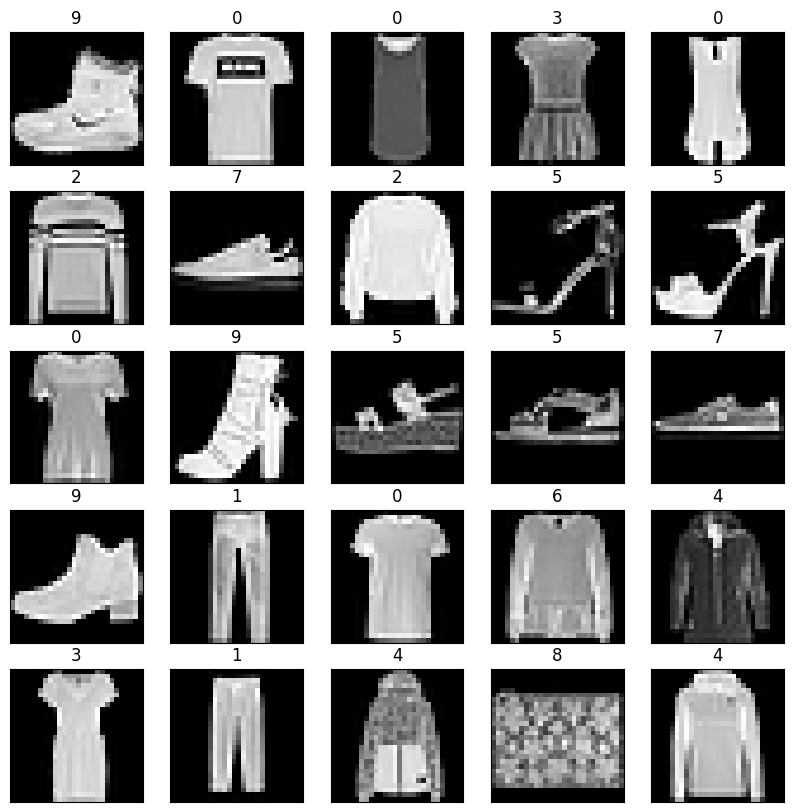

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(y_train[i])
plt.show()


In [ ]:
#Normalize Data (The comment below was written by ai if we keep this will want to write in our own words.)
#it’s repeated because normalization is a key part of data preparation,
#and this section is meant to summarize all preprocessing
#steps together (including reshaping, encoding, etc.). )
x_train = x_train / 255.0
x_test = x_test / 255.0

In [ ]:
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

In [ ]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import fashion_mnist

# Reload the original labels to ensure correct shape
(_, y_train_orig), (_, y_test_orig) = fashion_mnist.load_data()

# Convert Integer Labels (0-9) from one hot encoding label
y_train = to_categorical(y_train_orig, 10)
y_test = to_categorical(y_test_orig, 10)

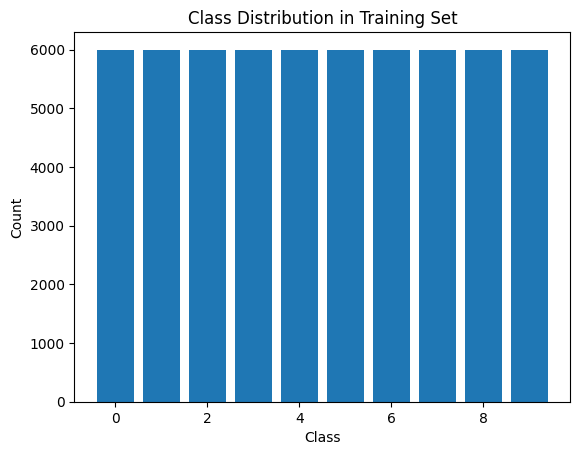

In [ ]:
# Check if classes are balanced
import numpy as np
import matplotlib.pyplot as plt

classes, counts = np.unique(y_train.argmax(axis=1), return_counts=True)
plt.bar(classes, counts)
plt.title("Class Distribution in Training Set")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [ ]:
#Optional Feature Engineering
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(rotation_range=10, zoom_range=0.1, horizontal_flip=True)
datagen.fit(x_train)

In [ ]:
#option 1 Dense Nueral Network (This is pasted as an example to determin which nueral network )
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

# Build the model
dense_model = Sequential([
    Flatten(input_shape=(28, 28, 1)),  # Flatten image to 1D
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')    # Output layer for 10 classes
])

# Compile the model
dense_model.compile(optimizer='adam',
                    loss='categorical_crossentropy',
                    metrics=['accuracy'])

# Train the model
dense_model.fit(x_train, y_train, epochs=10, validation_split=0.2)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5372 - loss: 1.3271 - val_accuracy: 0.7690 - val_loss: 0.6409
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7716 - loss: 0.6192 - val_accuracy: 0.7984 - val_loss: 0.5607
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8010 - loss: 0.5455 - val_accuracy: 0.8118 - val_loss: 0.5193
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8170 - loss: 0.5087 - val_accuracy: 0.8263 - val_loss: 0.4853
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8341 - loss: 0.4702 - val_accuracy: 0.8294 - val_loss: 0.4718
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8393 - loss: 0.4527 - val_accuracy: 0.8378 - val_loss: 0.4547
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8414 - loss: 0.4414 - val_accuracy: 0.8428 - val_loss: 0.4349
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8509 - loss: 0.4204 - 

In [ ]:
#Option 2 CNN Model
#from tensorflow.keras.models import Sequential
#from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Build the CNN model
#cnn_model = Sequential([
    #Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
    #MaxPooling2D(pool_size=(2,2)),
    #Conv2D(64, (3,3), activation='relu'),
    #MaxPooling2D(pool_size=(2,2)),
    #Flatten(),
    #Dense(128, activation='relu'),
    #Dropout(0.3),
    #Dense(10, activation='softmax')
#])

# Compile the model
#cnn_model.compile(optimizer='adam',
                  #loss='categorical_crossentropy',
                  #metrics=['accuracy'])

# Train the model
#cnn_model.fit(x_train, y_train, epochs=10, validation_split=0.2)

In [ ]:
#Regularization
from tensorflow.keras.layers import Dropout
# Already added Dropout in CNN model

In [ ]:
# Batch Normalization
from tensorflow.keras.layers import BatchNormalization
# Add after Conv or Dense layers

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau

# Re-build and re-compile the CNN model to ensure a clean state after previous errors
cnn_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='sigmoid')
])

cnn_model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)
cnn_model.fit(x_train, y_train, epochs=20, validation_split=0.2, callbacks=[lr_scheduler])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 48s 31ms/step - accuracy: 0.4101 - loss: 1.5699 - val_accuracy: 0.7300 - val_loss: 0.7095 - learning_rate: 0.0010
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 45s 30ms/step - accuracy: 0.7080 - loss: 0.7715 - val_accuracy: 0.7667 - val_loss: 0.6208 - learning_rate: 0.0010
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 82s 30ms/step - accuracy: 0.7425 - loss: 0.6836 - val_accuracy: 0.7902 - val_loss: 0.5601 - learning_rate: 0.0010
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 46s 31ms/step - accuracy: 0.7688 - loss: 0.6138 - val_accuracy: 0.7977 - val_loss: 0.5296 - learning_rate: 0.0010
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 45s 30ms/step - accuracy: 0.7760 - loss: 0.5898 - val_accuracy: 0.8074 - val_loss: 0.5118 - learning_rate: 0.0010
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 46s 31ms/step - accuracy: 0.7911 - loss: 0.5645 - val_accuracy: 0.8154 - val_loss: 0.4830 - learning_rate: 0.0010
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 47s 31ms/step - accura

The error indicates that validation_split cannot be used directly with data generated by ImageDataGenerator.flow(). To fix this, I will modify the code to define the validation_split within the ImageDataGenerator and then create separate generators for the training and validation subsets. These generators will then be passed to the fit method.

In [ ]:
# Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=10, #rotates up to 10 degrees CW or CCW
    zoom_range=0.1, # zooms in or out by 10 times
    horizontal_flip=True, # enables mirroring left or right
    validation_split=0.2 # Takes 20% of the training dataset
)

# Create training and validation generators
train_generator = datagen.flow(x_train, y_train, batch_size=64, subset='training')
validation_generator = datagen.flow(x_train, y_train, batch_size=64, subset='validation')

# Fit the model using the generators, removing validation_split from .fit()
cnn_model.fit(train_generator,
              epochs=10,
              validation_data=validation_generator)

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


750/750 ━━━━━━━━━━━━━━━━━━━━ 57s 74ms/step - accuracy: 0.7524 - loss: 0.7585 - val_accuracy: 0.8285 - val_loss: 0.4572
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.7923 - loss: 0.5575 - val_accuracy: 0.8311 - val_loss: 0.4501
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.8045 - loss: 0.5257 - val_accuracy: 0.8297 - val_loss: 0.4425
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 74ms/step - accuracy: 0.8080 - loss: 0.5111 - val_accuracy: 0.8329 - val_loss: 0.4334
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 56s 75ms/step - accuracy: 0.8115 - loss: 0.5145 - val_accuracy: 0.8432 - val_loss: 0.4202
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.8135 - loss: 0.5058 - val_accuracy: 0.8413 - val_loss: 0.4195
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.8177 - loss: 0.5006 - val_accuracy: 0.8457 - val_loss: 0.4145
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.8179 - loss: 0.4876 - val_accurac

The error ValueError: Argument validation_split is only supported for tensors or NumPy arrays happens because you're trying to use validation_split with a data generator from ImageDataGenerator.flow(), which isn't supported. The fit() method expects validation data to be provided separately as a generator via validation_data in such cases. Additionally, the comment indicates you want to evaluate the test set, but the code is performing another training step. I'll correct this by changing the code to properly evaluate the model on the test data.

In [ ]:
# Evaluate Test Set
loss, accuracy = cnn_model.evaluate(x_test, y_test)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8639 - loss: 0.3761
Test Loss: 0.3797
Test Accuracy: 0.8640


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step


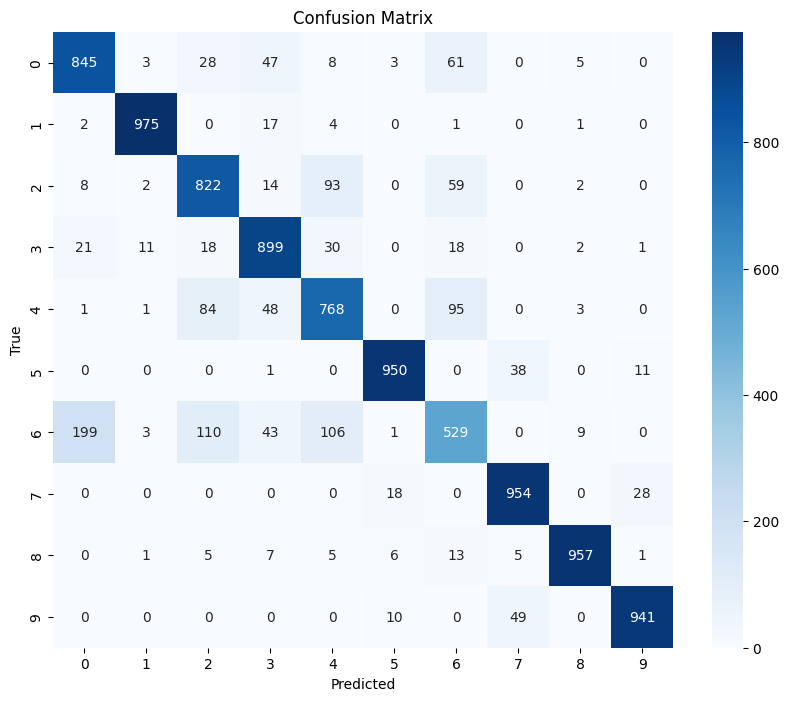

In [ ]:
#Visualise Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

y_pred = cnn_model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

(3, 3, 1, 32)


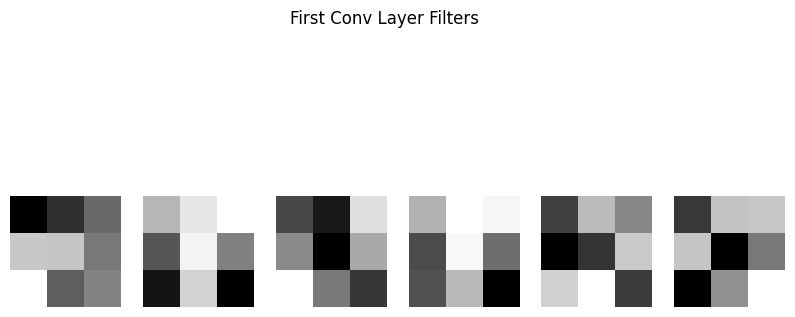

In [ ]:
#Visualize CNN Filters
# Get weights of first Conv layer
filters, biases = cnn_model.layers[0].get_weights()
print(filters.shape)  # (3, 3, 1, 32)

# Normalize filter values for visualization
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

import matplotlib.pyplot as plt

# Plot first 6 filters
n_filters = 6
plt.figure(figsize=(10, 5))
for i in range(n_filters):
    plt.subplot(1, n_filters, i+1)
    plt.imshow(filters[:, :, 0, i], cmap='gray')
    plt.axis('off')
plt.suptitle('First Conv Layer Filters')
plt.show()

The error The layer sequential_5 has never been called means that when we tried to create a new model to visualize feature maps, the main cnn_model's input layer wasn't accessible in the way Keras expected, even though the model was previously trained. To fix this, I'll explicitly pass a dummy input through the cnn_model right before creating the feature visualization model. This will ensure its internal graph is fully defined and its input is accessible.

In [ ]:
# # Visualize Feature Maps
# from tensorflow.keras.models import Model
# import numpy as np
# import tensorflow as tf # Import tensorflow

# # Ensure the model is built and its input/output tensors are defined
# # by passing a dummy input through it.
# # This explicitly "calls" the model, resolving "has never been called" error.
# _ = cnn_model(tf.zeros([1, 28, 28, 1])) # Pass a dummy input to build the model's graph

# # Create a model that outputs feature maps from first Conv layer
# layer_outputs = [layer.output for layer in cnn_model.layers[:2]]  # First Conv + Pool
# activation_model = Model(inputs=cnn_model.input, outputs=layer_outputs)

# # Pick one image from test set
# img = x_test[0].reshape(1, 28, 28, 1)
# activations = activation_model.predict(img)

# # Plot feature maps from first Conv layer
# first_layer_activation = activations[0]
# n_features = first_layer_activation.shape[-1]

# import matplotlib.pyplot as plt # Ensure plt is imported here if not globally

# plt.figure(figsize=(15, 15))
# for i in range(min(n_features, 16)):  # Show first 16 maps
#     plt.subplot(4, 4, i+1)
#     plt.imshow(first_layer_activation[0, :, :, i], cmap='gray')
#     plt.axis('off')
# plt.suptitle('Feature Maps from First Conv Layer')
# plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Accuracy for the 25 visualized samples: 0.9200


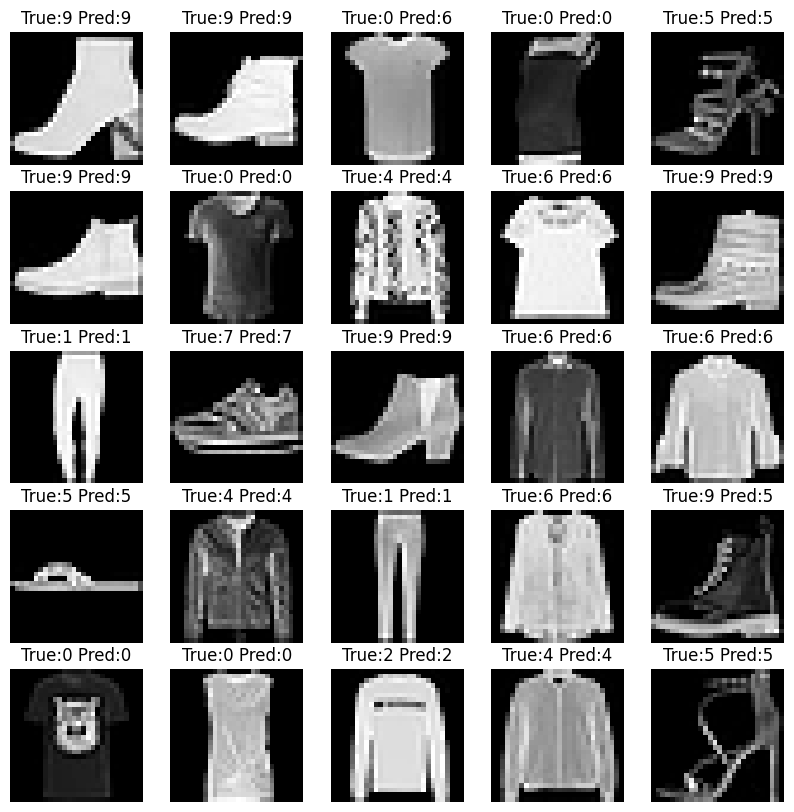

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Generate random indices for 25 samples
num_samples = 25
random_indices = np.random.choice(len(x_test), num_samples, replace=False)

# Select random samples from x_test and y_test
sampled_x_test = x_test[random_indices]
sampled_y_test = y_test[random_indices]

predictions = dense_model.predict(sampled_x_test)
pred_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(sampled_y_test, axis=1)

# Calculate accuracy for the visualized samples
sample_accuracy = accuracy_score(true_classes, pred_classes)
print(f"Accuracy for the {len(true_classes)} visualized samples: {sample_accuracy:.4f}")

plt.figure(figsize=(10,10))
for i in range(num_samples):
    plt.subplot(5,5,i+1)
    plt.imshow(sampled_x_test[i].reshape(28,28), cmap='gray')
    plt.title(f"True:{true_classes[i]} Pred:{pred_classes[i]}")
    plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Accuracy for the 25 visualized samples: 0.9200


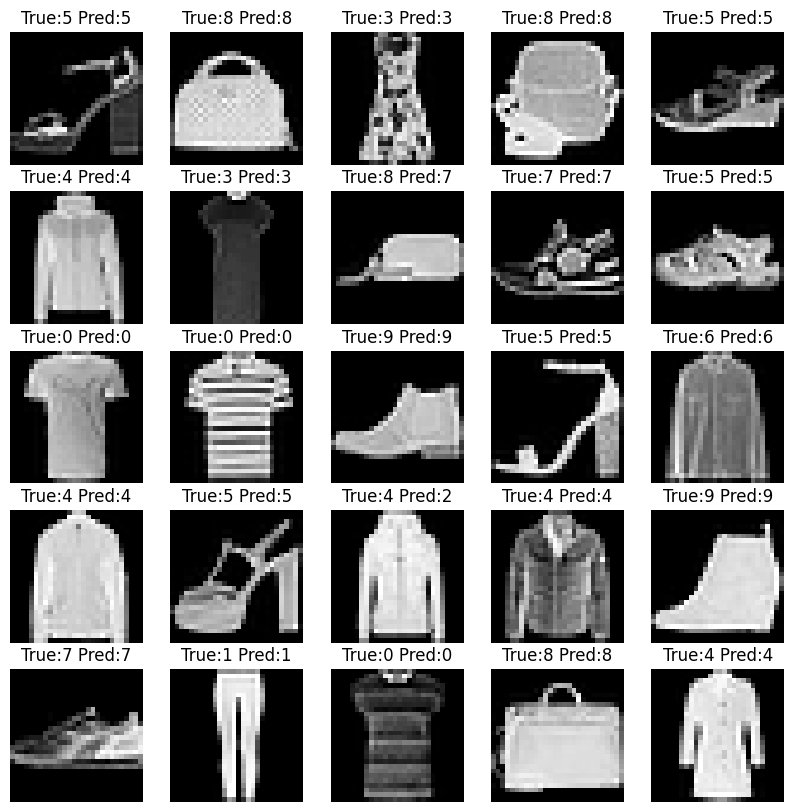

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Generate random indices for 25 samples
num_samples = 25
random_indices = np.random.choice(len(x_test), num_samples, replace=False)

# Select random samples from x_test and y_test
sampled_x_test = x_test[random_indices]
sampled_y_test = y_test[random_indices]

predictions = dense_model.predict(sampled_x_test)
pred_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(sampled_y_test, axis=1)

# Calculate accuracy for the visualized samples
sample_accuracy = accuracy_score(true_classes, pred_classes)
print(f"Accuracy for the {len(true_classes)} visualized samples: {sample_accuracy:.4f}")

plt.figure(figsize=(10,10))
for i in range(num_samples):
    plt.subplot(5,5,i+1)
    plt.imshow(sampled_x_test[i].reshape(28,28), cmap='gray')
    plt.title(f"True:{true_classes[i]} Pred:{pred_classes[i]}")
    plt.axis('off')
plt.show()

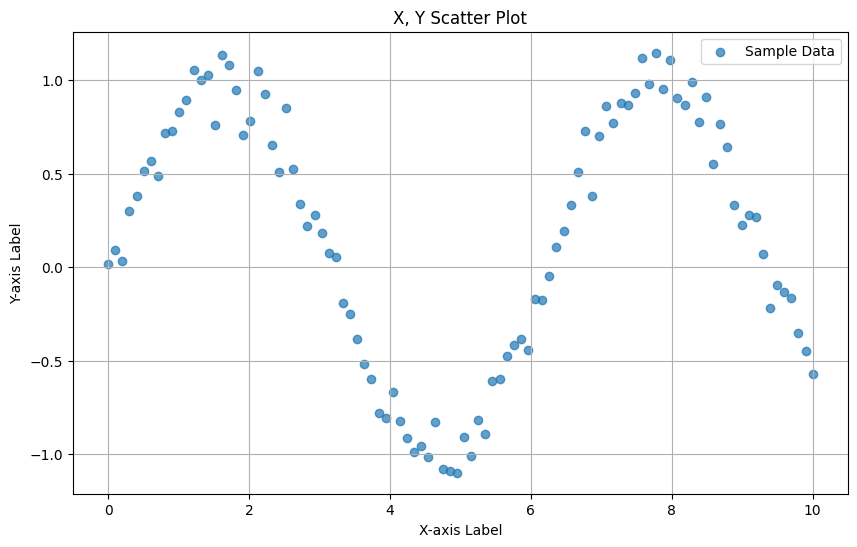

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Example data (replace with your actual data)
x_data = np.linspace(0, 10, 100)
y_data = np.sin(x_data) + np.random.normal(0, 0.1, 100)

plt.figure(figsize=(10, 6))
plt.scatter(x_data, y_data, label='Sample Data', alpha=0.7)
plt.title('X, Y Scatter Plot')
plt.xlabel('X-axis Label')
plt.ylabel('Y-axis Label')
plt.grid(True)
plt.legend()
plt.show()

This code generates a scatter plot. If you prefer a line plot (for time series data, for example), you can change `plt.scatter` to `plt.plot`:

```python
import matplotlib.pyplot as plt
import numpy as np

# Example data for a line plot
x_data_line = np.linspace(0, 10, 100)
y_data_line = np.cos(x_data_line) + x_data_line * 0.1

plt.figure(figsize=(10, 6))
plt.plot(x_data_line, y_data_line, label='Line Data', color='red')
plt.title('X, Y Line Plot')
plt.xlabel('X-axis Label')
plt.ylabel('Y-axis Label')
plt.grid(True)
plt.legend()
plt.show()
```